In [1]:
import numpy as np
import torch as tc
import numpy.random as rd
import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx
import argparse
import linear_er


from circuit_solver import circuit as ct
from circuit_solver import elements as es
from circuit_solver import utils
from circuit_solver.learning import CoupledLearning, SymmetricCoupledLearning, CLTrainingConfig, CLTestingConfig, CoupledLearningEtaZero
mpl.rcParams['text.usetex'] = True
mpl.rcParams['font.family'] = 'serif'

In [12]:
seed = 1    # RNG seed for graph, model and data generation
N = 5
M = 5
N_h = 5
p = 0.05
eta_values = [0., 1.]

N_eta = len(eta_values)
er = linear_er.new(N=N, M=M, N_h=N_h, p=p, seed=seed)
er.model.set_absorbing()
# er_ = [linear_er.new(N=N, M=M, N_h=N_h, p=p) for n in range(N_eta)]

In [13]:
P = 40         # number of samples
alpha_power = 1.0  # power-law exponent for eigenvalues: λ_i ∝ i^(-α)

dims = N + M
eigenvalues = (np.arange(1, dims + 1, dtype=float)) ** (-alpha_power)

# Random orthogonal basis via QR
rng = np.random.default_rng(seed)
Q, _ = np.linalg.qr(rng.standard_normal((dims, dims)))
cov = Q @ np.diag(eigenvalues) @ Q.T

Z = rng.multivariate_normal(np.zeros(dims), cov, size=P).astype(np.float32)
X_data = Z[:, :N]
Y_data = Z[:, N:]

print(f"X_data: {X_data.shape},  Y_data: {Y_data.shape}")

X_data: (40, 5),  Y_data: (40, 5)


In [14]:
np.log10(eigenvalues)

array([ 0.        , -0.30103   , -0.47712125, -0.60205999, -0.69897   ,
       -0.77815125, -0.84509804, -0.90308999, -0.95424251, -1.        ])

In [15]:
alpha = 0.2
N_batches = 2000
batch_size = P

histories = []
for eta in (eta_values):
    er.model.reset()
    config = CLTrainingConfig(
        batch_size=batch_size,
        N_batches=N_batches,
        alpha=alpha,
        eta=eta,
    )
    learner = CoupledLearningEtaZero if eta == 0 else CoupledLearning
    print(f"Training  eta={eta}  ({learner.__name__})")
    histories.append(learner(X_data, Y_data, er.model, config))

Training  eta=0.0  (CoupledLearningEtaZero)


100%|██████████| 2000/2000 [00:23<00:00, 85.43it/s]


Training  eta=1.0  (CoupledLearning)


100%|██████████| 2000/2000 [00:12<00:00, 163.29it/s]


In [16]:
# y_edge_inds = utils.get_edges_between(er.internal_nodes, er.y_nodes, er.circuit)
# y_edge_inds = utils.edges_to_inds(y_edge_inds, er.circuit)


y_edge_inds = []
non_y_edge_inds = []
for i, (u, v) in enumerate(er.element_dict[er.out_element]):
    if u in er.y_nodes or v in er.y_nodes:
        y_edge_inds.append(i)
    else:
        non_y_edge_inds.append(i)


# Note on $\eta$ convention

The convention used in the code base (`circuit-solver`) is that positive $\eta$ pushes the outputs towards the desired target state. In the paper, the opposite sign convention is used. This is the reason why the plots below have a mismatch between label and variable definition.

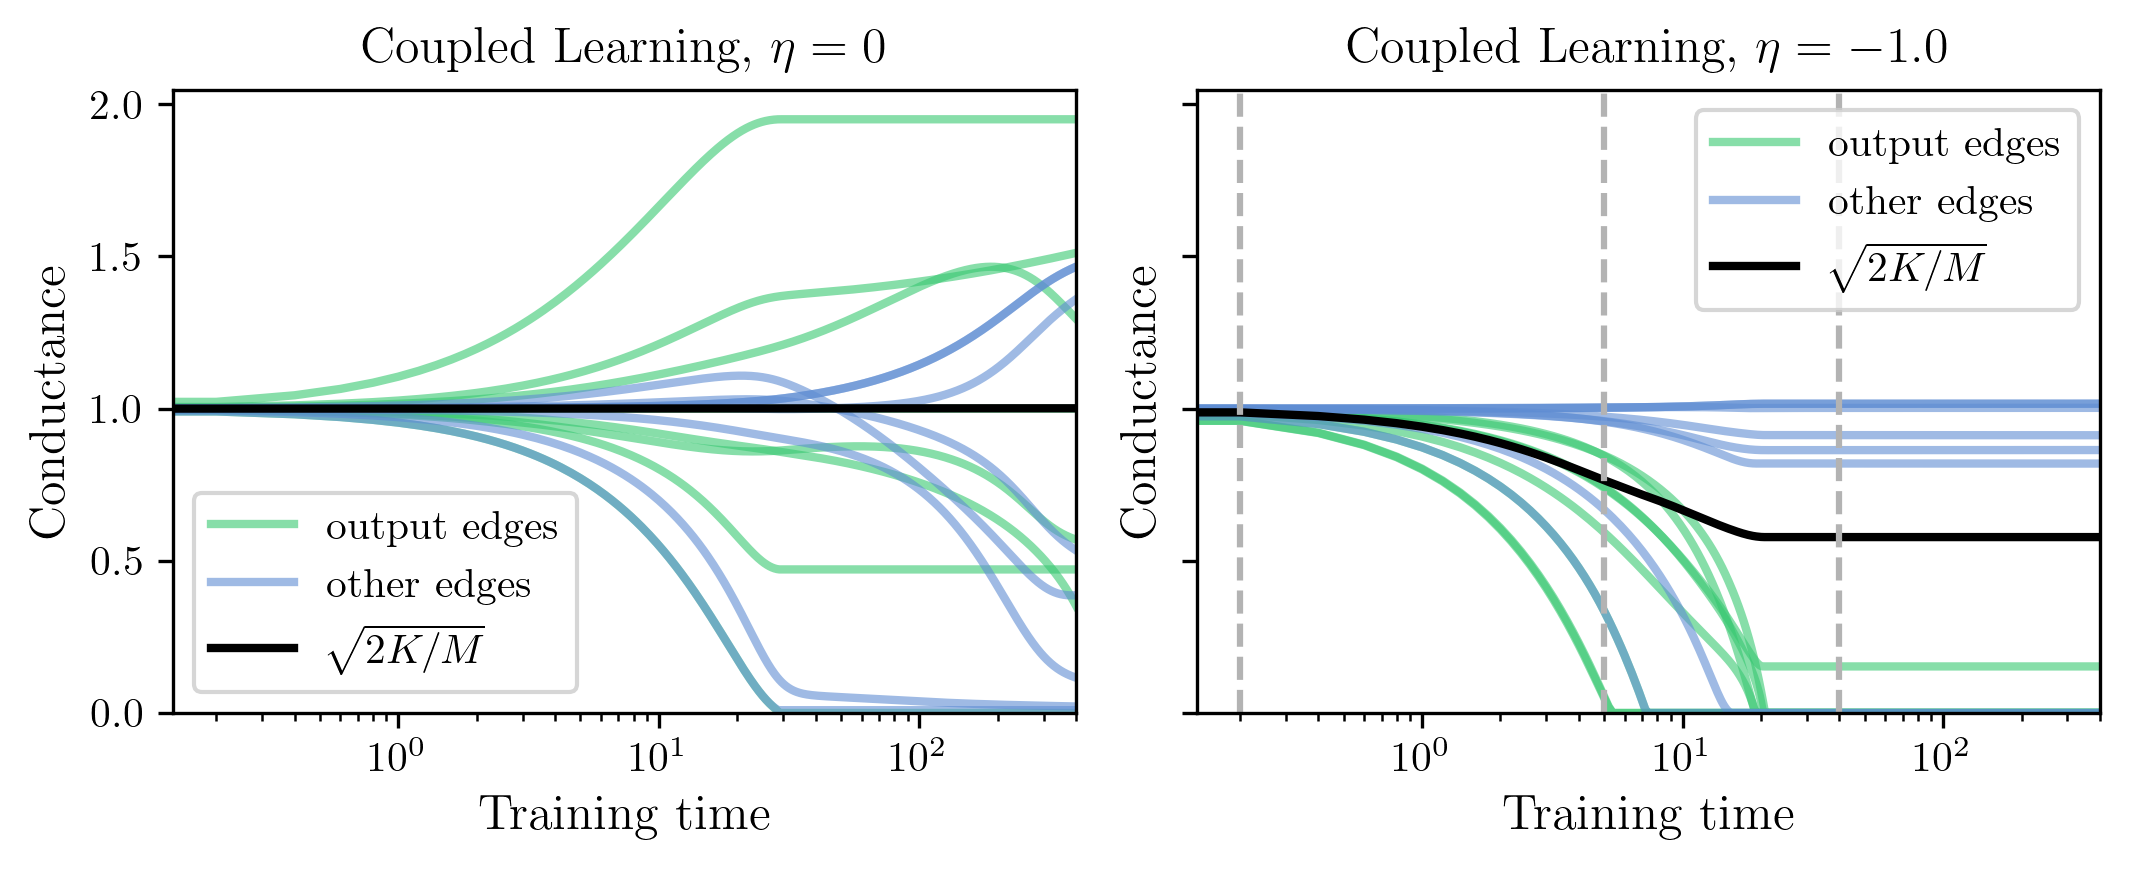

In [ ]:
c1 = "#37c871"
c2 = "#5f8dd3"

key_frames = [1, 25, 200]
sz = 1.2
plot_alp = 0.6
# N_eta = 1
N_eta = len(eta_values)
fig, axes = plt.subplots(1, N_eta, figsize=(3 * sz * N_eta, 2.5 * sz), dpi=300, sharey=True)

color = (0.5,0.5,0.5)
lw = 2
for ax, history, eta in zip(axes, histories, eta_values):
    G = history['out']   # shape (N*M, N_batches+1): each row is one conductance trajectory
    steps = np.arange(G.shape[1])
    for g in G:
        # g = G[0]
        g1 = g[:, y_edge_inds]
        g2 = g[:, non_y_edge_inds]

        K = np.sqrt(np.mean(g**2, axis=1))

        ax.semilogx(steps * alpha, g1, linewidth=lw, alpha=plot_alp, color=c1)
        ax.semilogx([], [], linewidth=lw, alpha=plot_alp, color=c1, label='output edges')

        ax.semilogx(steps * alpha, g2, linewidth=lw, alpha=plot_alp, color=c2)
        ax.semilogx([], [], linewidth=lw, alpha=plot_alp, color=c2, label='other edges')

        ax.plot(steps * alpha, K, linewidth=lw, color='k', label='$\\sqrt{2K/M}$')

    # ax.plot(steps * alpha, g, linewidth=lw, alpha=plot_alp, color=color)
    # ax.plot([], [], linewidth=lw, alpha=plot_alp, color=color, label='$\\kappa_{ij}$')
    # ax.plot(steps * alpha, K, linewidth=lw, color='blue', label='$\\sqrt{2K/M}$')

    ax.set_ylim(0)
    # ax.set_xlim(0,20)
    ax.set_xlim(xmax=steps[-1]*alpha)
    ax.set_xlabel('Training time', size=12)
    lbl = -eta if eta != 0 else 0
    ax.set_title(f'Coupled Learning, $\\eta = {lbl}$')
    ax.legend()

    ax.set_ylabel('Conductance', size=12)

for f in key_frames:
    axes[-1].axvline(f * alpha, ls='--', color=(0.7, 0.7, 0.7))

plt.tight_layout()
# plt.show()
# plt.savefig('plots/er_trajectories.png', dpi=1000, transparent=True)

In [18]:
def draw_arc(ax, start, end, n_points=100, **kwargs):
    """Draw a circular arc connecting start and end (points on a circle centered
    at the origin) that meets the circle perpendicularly at both endpoints."""
    P1 = np.array(start, dtype=float)
    P2 = np.array(end, dtype=float)

    # Degenerate case: points are (nearly) identical
    if np.linalg.norm(P2 - P1) < 1e-12:
        return

    # Solve C·P1 = |P1|², C·P2 = |P2|²  (orthogonality conditions)
    A = np.array([P1, P2])
    b = np.array([P1 @ P1, P2 @ P2])

    if abs(np.linalg.det(A)) < 1e-12:
        # Diametrically opposite – draw a straight line
        ax.plot([P1[0], P2[0]], [P1[1], P2[1]], **kwargs)
        return

    C = np.linalg.solve(A, b)
    r = np.linalg.norm(C - P1)

    # Angles relative to arc-circle center
    a1 = np.arctan2(P1[1] - C[1], P1[0] - C[0])
    a2 = np.arctan2(P2[1] - C[1], P2[0] - C[0])

    # Shorter arc
    da = (a2 - a1 + np.pi) % (2 * np.pi) - np.pi  # wrap to (-π, π]

    t = np.linspace(0, da, n_points)
    x = C[0] + r * np.cos(a1 + t)
    y = C[1] + r * np.sin(a1 + t)
    ax.plot(x, y, **kwargs)

In [19]:
# node positions — three groups spaced around the circle with gaps
groups = [er.x_nodes, er.hidden_nodes, er.y_nodes]
N_groups = len(groups)
gap = 0.3  # radians between groups
arc = (2 * np.pi - N_groups * gap) / N_groups  # arc per group

pos = {}
offset = gap / 2
for group in groups:
    n_g = len(group)
    angles = np.linspace(offset, offset + arc, n_g, endpoint=False) + arc / (2 * n_g)
    for node, a in zip(group, angles):
        pos[node] = (np.cos(a), np.sin(a))
    offset += arc + gap

# node colors
node_color_map = {n: "r" for n in er.x_nodes}
node_color_map.update({n: "grey" for n in er.hidden_nodes})
node_color_map.update({n: "blue" for n in er.y_nodes})
node_color_map[er.GROUND[0]] = "k"
node_colors = [node_color_map[n] for n in er.graph.nodes()]

# edge colors
def kappa_to_color(i, kappa):
    if i in y_edge_inds:
        color = c1
    else: 
        color = c2
        
    color = mpl.colors.to_rgb(color)
    kappa_init = g[0, i]
    kappa_alpha = np.float64(np.min((kappa, kappa_init)))
    color = color + (kappa_alpha,)

    if kappa > 0:
        return color
    else:
        return (1,1,1,0)

# get edge colors
def update_edge_colors(history, t):
    kappa = history["out"][0, t, :]
    edge_color_map = {}
    for i, (u, v) in enumerate(er.circuit.edges()):
        edge_color_map[(u, v)] = kappa_to_color(i, kappa[i])
    return edge_color_map

(np.float64(-1.0973111908859665),
 np.float64(1.0435350086052615),
 np.float64(-1.085110782233858),
 np.float64(1.085110782233858))

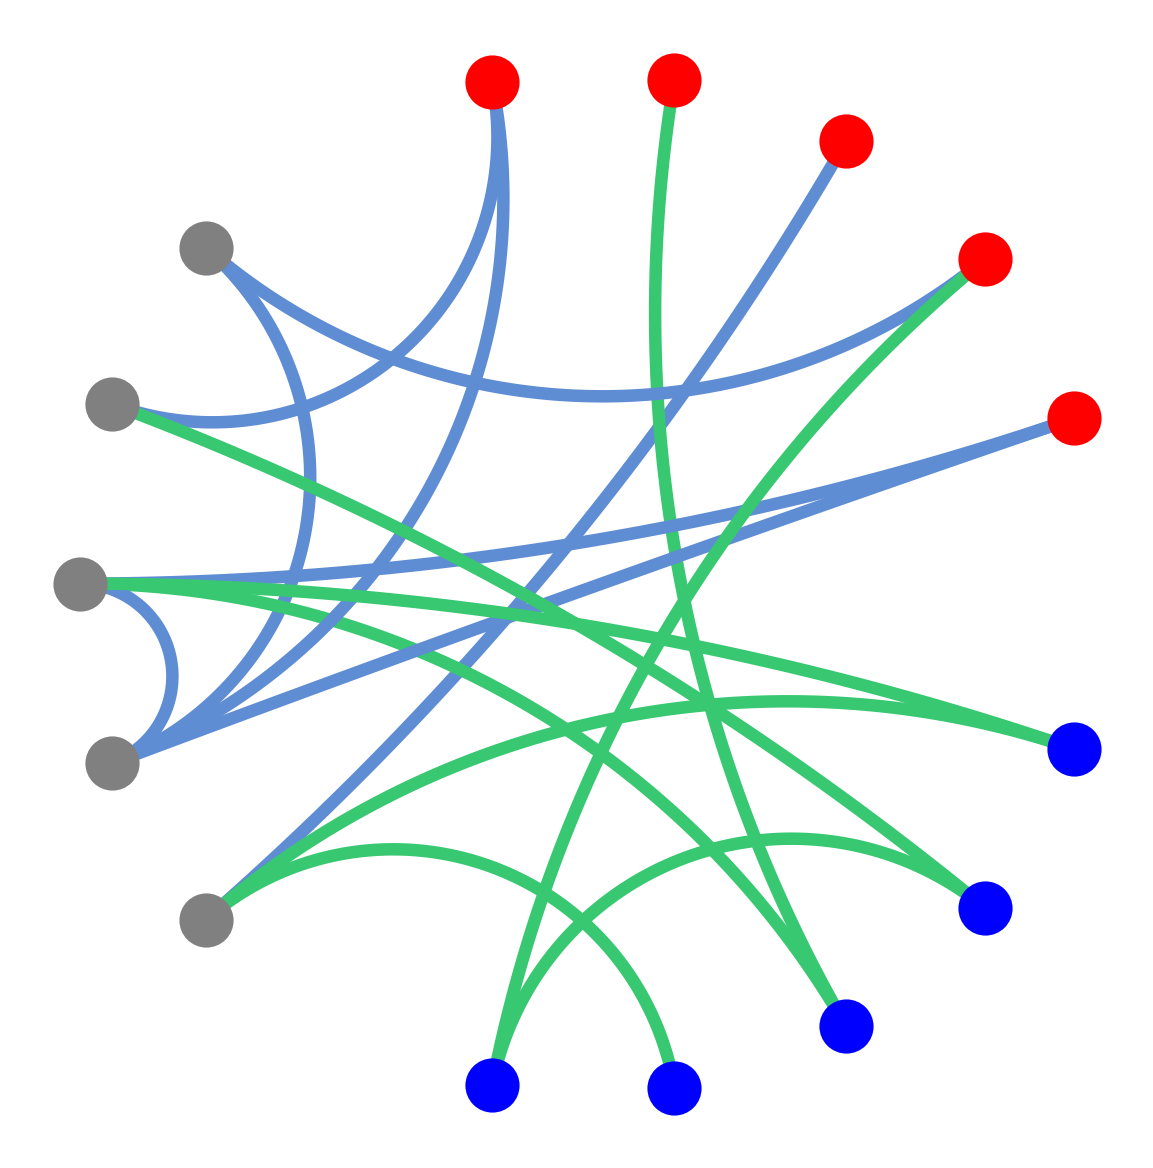

In [20]:
ms = 12
lw = 3
t = 10
l_alpha = 1

fig, ax = plt.subplots(dpi=300)

edge_color_map = update_edge_colors(histories[1], t)
for i, (u, v) in enumerate(er.circuit.edges):
    if u in er.fixed_nodes or v in er.fixed_nodes:
        continue
    cur_color = edge_color_map[(u, v)]
    draw_arc(ax, start=pos[u], end=pos[v], color=cur_color, lw=lw, alpha=l_alpha)
    

for i, n in enumerate(er.internal_nodes):
    cur_pos = pos[n]
    cur_color = node_color_map[n]
    ax.plot(*cur_pos, color=cur_color, marker='o', ms=ms)

ax.set_aspect('equal')
ax.axis('off')


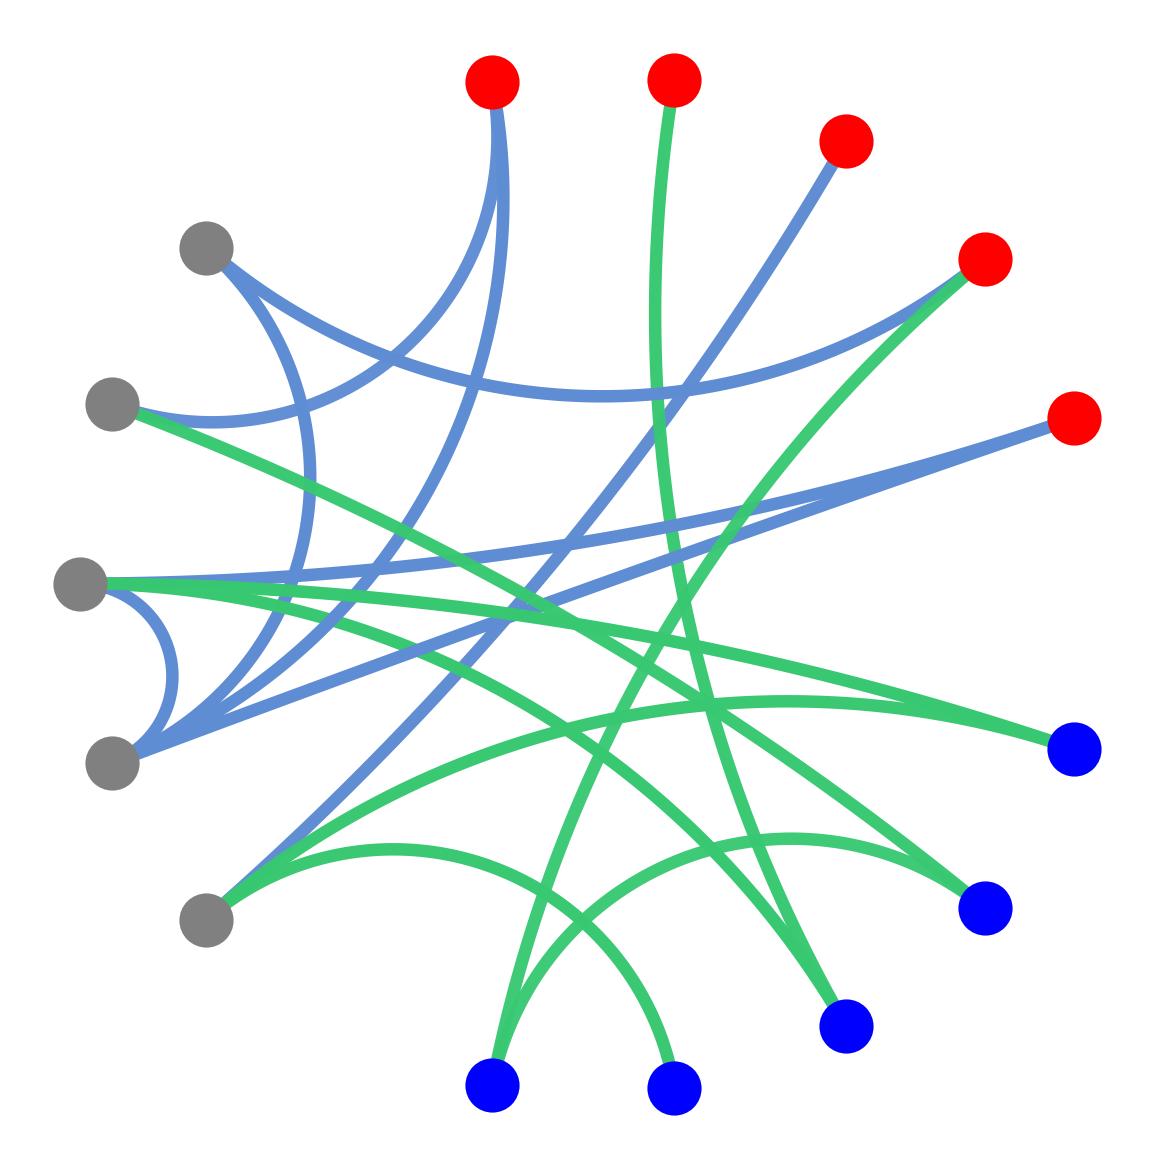

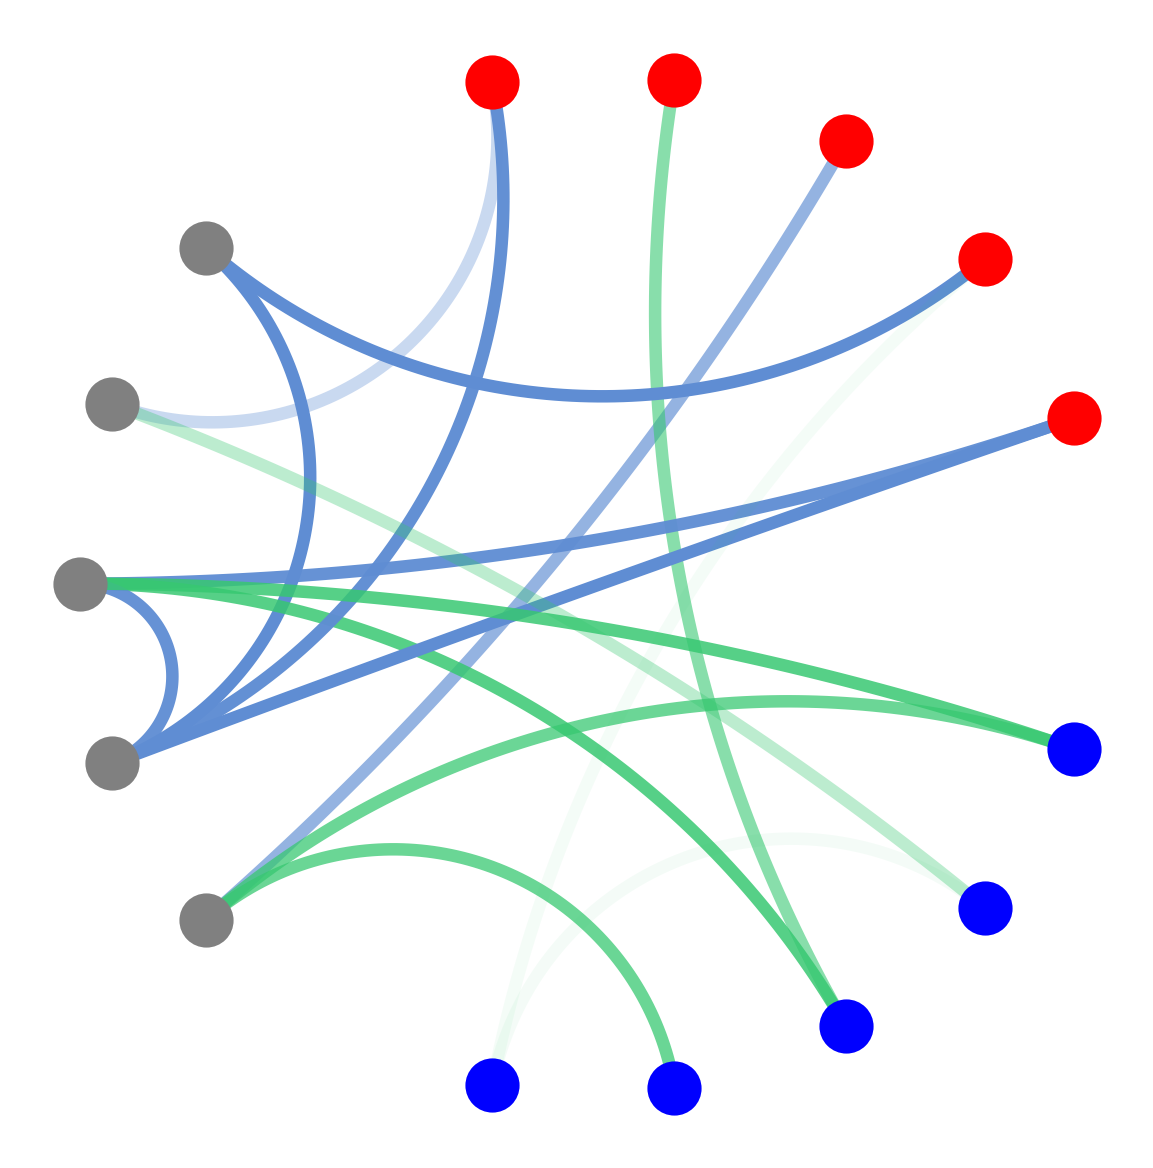

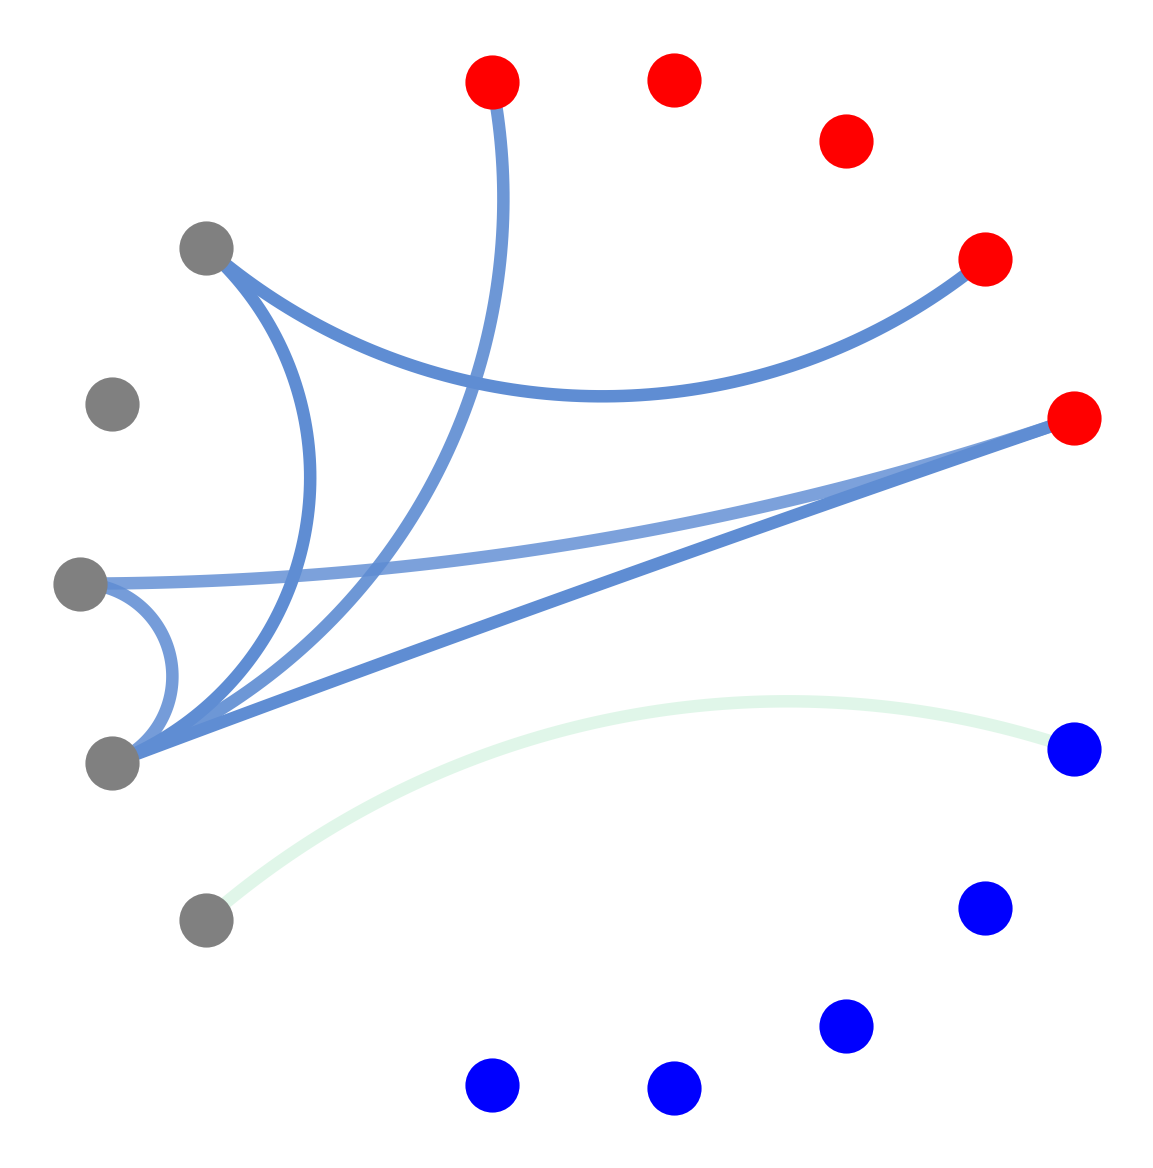

In [21]:
for t in key_frames:
    fig, ax = plt.subplots(dpi=300)

    edge_color_map = update_edge_colors(histories[1], t)
    for i, (u, v) in enumerate(er.circuit.edges):
        if u in er.fixed_nodes or v in er.fixed_nodes:
            continue
        cur_color = edge_color_map[(u, v)]
        draw_arc(ax, start=pos[u], end=pos[v], color=cur_color, lw=lw)
        
    for i, n in enumerate(er.internal_nodes):
        cur_pos = pos[n]
        cur_color = node_color_map[n]
        ax.plot(*cur_pos, color=cur_color, marker='o', ms=ms)

    ax.set_aspect('equal')
    ax.axis('off')
    # plt.savefig(f'plots/connection_plot_{t}.png', transparent=True, dpi=1000)